# **Week Six - Assignment Data Sets**

Name: Guillermo Schneider
Link: https://networkx.org/documentation/stable/auto_examples/algorithms/plot_davis_club.html
Dataset: These data were collected by Davis et al. in the 1930s. They represent observed attendance at 14 social events by 18 Southern women. The graph is bipartite (clubs, women). The attendance of a group of women (primary node set) to a series of events (secondary node set). A woman would be linked to an event if she attended it.

What can you infer about the relationships between (1) the women, and (2) the social events?  

In [2]:
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import bipartite
from itertools import combinations

In [3]:
G = nx.davis_southern_women_graph()

#primary or top set is considered more responsible for tie creation
women = G.graph["top"]
#rather than the secondary or bottom node set
clubs = G.graph["bottom"]

In [132]:
#Biadjacency matrix shows the relationship between the 18 women and the 14 social events, and which events they went to
#print("Biadjacency matrix")
#print(bipartite.biadjacency_matrix(G, women, clubs))

In [5]:
# project bipartite graph onto women nodes
# Two women are connected if they attended at least one social event together. 
# answers have they ever met each other before?
W = bipartite.projected_graph(G, women)
print()
print("#Friends, Member")
for w in women:
    print(f"{W.degree(w)} {w}")


#Friends, Member
17 Evelyn Jefferson
15 Laura Mandeville
17 Theresa Anderson
15 Brenda Rogers
11 Charlotte McDowd
15 Frances Anderson
15 Eleanor Nye
16 Pearl Oglethorpe
17 Ruth DeSand
17 Verne Sanderson
16 Myra Liddel
16 Katherina Rogers
17 Sylvia Avondale
17 Nora Fayette
17 Helen Lloyd
16 Dorothy Murchison
12 Olivia Carleton
12 Flora Price


In [6]:
# project bipartite graph onto women nodes keeping number of co-occurrence
# the degree computed is weighted and counts the total number of shared contacts. 
# how many times have they met each other?
W = bipartite.weighted_projected_graph(G, women)
print()
print("#Friend meetings, Member")
for w in women:
    print(f"{W.degree(w, weight='weight')} {w}")


#Friend meetings, Member
50 Evelyn Jefferson
45 Laura Mandeville
57 Theresa Anderson
46 Brenda Rogers
24 Charlotte McDowd
32 Frances Anderson
36 Eleanor Nye
31 Pearl Oglethorpe
40 Ruth DeSand
38 Verne Sanderson
33 Myra Liddel
37 Katherina Rogers
46 Sylvia Avondale
43 Nora Fayette
34 Helen Lloyd
24 Dorothy Murchison
14 Olivia Carleton
14 Flora Price


In [7]:
# Create a dictionary mapping each woman to her attendance count (degree)
attendance = {woman: G.degree(woman) for woman in women}
sorted_attendance = sorted(attendance.items(), key=lambda item: item[1], reverse=True)

print("Events Attended, Woman")
for woman, count in sorted_attendance:
    print(f"{count} {woman}")

Events Attended, Woman
8 Evelyn Jefferson
8 Theresa Anderson
8 Nora Fayette
7 Laura Mandeville
7 Brenda Rogers
7 Sylvia Avondale
6 Katherina Rogers
5 Helen Lloyd
4 Charlotte McDowd
4 Frances Anderson
4 Eleanor Nye
4 Ruth DeSand
4 Verne Sanderson
4 Myra Liddel
3 Pearl Oglethorpe
2 Dorothy Murchison
2 Olivia Carleton
2 Flora Price


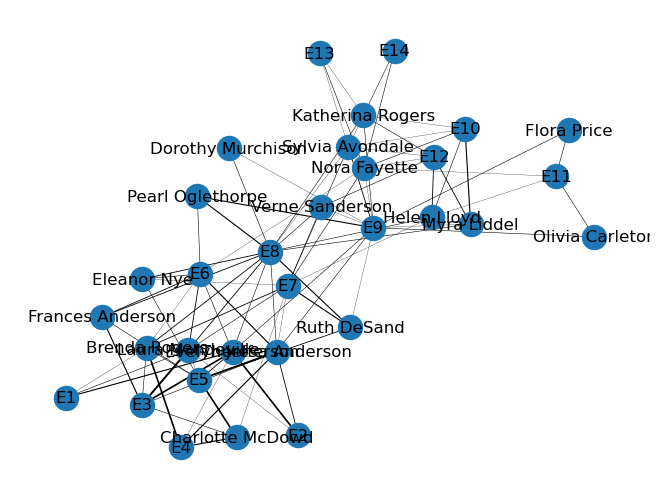

In [8]:
pos = nx.spring_layout(G, seed=648)  # Seed layout for reproducible node positions
weights = [W[u][v].get('weight', 1) / 5 for u, v in W.edges()]
nx.draw(G, pos,with_labels=True,width=weights)
plt.show()

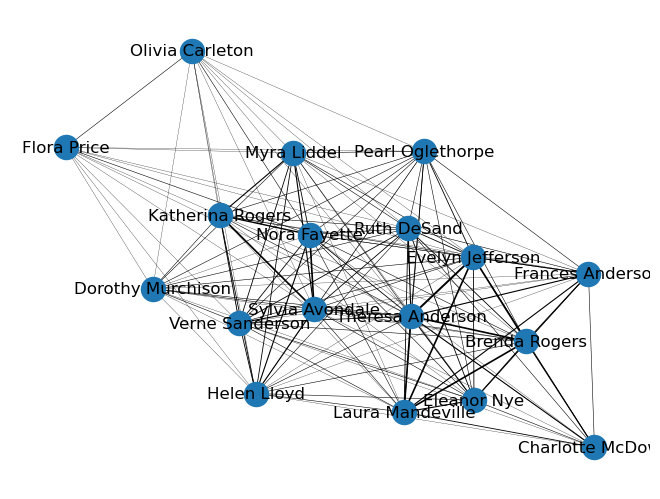

In [9]:
pos = nx.spring_layout(W, seed=648)  # Seed layout for reproducible node positions
weights = [W[u][v].get('weight', 1)/ 5 for u, v in W.edges()]
nx.draw(W, pos,with_labels=True,width=weights)
plt.show()

Cliques: This isnt useful. Almost all the women interacted with each other, so they're not seperated subgraphs. I need to instead filter for groups that went to atleast a certain amount of events together.

In [10]:
#a subset of vertices such that every two distinct vertices are adjacent (forming a complete subgraph)
cliques = list(nx.find_cliques(W))

# Print the found cliques
for i, clique in enumerate(cliques, 1):
    print(f"Clique {i}: {clique}")

Clique 1: ['Verne Sanderson', 'Helen Lloyd', 'Evelyn Jefferson', 'Sylvia Avondale', 'Ruth DeSand', 'Nora Fayette', 'Theresa Anderson', 'Charlotte McDowd', 'Frances Anderson', 'Eleanor Nye', 'Laura Mandeville', 'Brenda Rogers']
Clique 2: ['Verne Sanderson', 'Helen Lloyd', 'Evelyn Jefferson', 'Sylvia Avondale', 'Ruth DeSand', 'Nora Fayette', 'Theresa Anderson', 'Myra Liddel', 'Pearl Oglethorpe', 'Dorothy Murchison', 'Katherina Rogers', 'Frances Anderson', 'Eleanor Nye', 'Laura Mandeville', 'Brenda Rogers']
Clique 3: ['Verne Sanderson', 'Helen Lloyd', 'Evelyn Jefferson', 'Sylvia Avondale', 'Ruth DeSand', 'Nora Fayette', 'Theresa Anderson', 'Myra Liddel', 'Pearl Oglethorpe', 'Dorothy Murchison', 'Katherina Rogers', 'Olivia Carleton', 'Flora Price']


In [11]:
W_filtered = nx.Graph() #new graph
W_filtered.add_nodes_from(W.nodes())
for u, v, data in W.edges(data=True):
    if data['weight'] >= 4: #where women went to atleast 4 events together
        W_filtered.add_edge(u, v)

cliques = list(nx.find_cliques(W_filtered)) #find the cliques in this new group

In [12]:
print("Cliques where they shares at least 4 events:")
for i, clique in enumerate(cliques, 1):
    if len(clique) >= 3: #just look for 3 person+ groups
        print(f"Clique {i}: {clique}")

Cliques where they shares at least 4 events:
Clique 3: ['Myra Liddel', 'Sylvia Avondale', 'Katherina Rogers']
Clique 7: ['Sylvia Avondale', 'Nora Fayette', 'Katherina Rogers']
Clique 8: ['Sylvia Avondale', 'Nora Fayette', 'Helen Lloyd']
Clique 10: ['Theresa Anderson', 'Brenda Rogers', 'Charlotte McDowd']
Clique 11: ['Theresa Anderson', 'Brenda Rogers', 'Laura Mandeville', 'Frances Anderson', 'Evelyn Jefferson']
Clique 12: ['Theresa Anderson', 'Brenda Rogers', 'Laura Mandeville', 'Eleanor Nye']


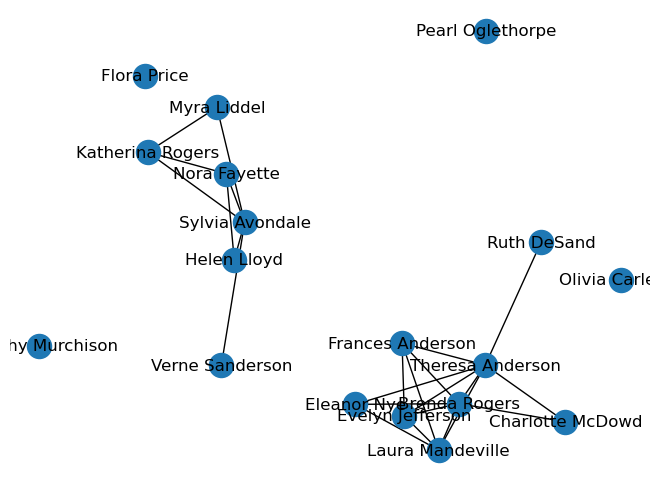

In [13]:
#Strong connection between women who went to atleast 4 events together
pos = nx.spring_layout(W_filtered,k=0.8, seed=648)  # Seed layout for reproducible node positions
nx.draw(W_filtered, pos,with_labels=True,)
plt.show()

Questions:

- Who has the most connections? 8 of the 18 women were able to meet every other woman over these events. Evelyn Jefferson, Theresa Anderson, Ruth DeSand, Sylvia Avondale, Verne Sanderson, Sylvia Avondale, Nora Fayette, and Helen Lloyd all had 17 total connections.
  
- Who had the least connections? Charlotte McDowd,  Olivia Carleton, Flora Price all met the least women over these events but still met 11 or 12 of them total, meaning there was pretty "regular" group.

- Who went to the most events? Evelyn Jefferson, Theresa Anderson, Nora Fayette all went to 8 events (of the 14 events), the most of all of the women. All three of were able to meet everyone in about half the meetups.

- Who went to the least events? Dorothy Murchison, Olivia Carleton, Flora Price each went to only 2 events, the least of all the women. It's interesting that Olivia and Flora both also had the least connections total, but still met 11 people total at only 2 events, these are well attended events. 

- Who has met the most people the most times? Theresa Anderson (57) and Evelyn Jefferson (50) have interacted with the most women the most times total. They have interacted with the the whole group of 17 women many times over the 8 events they've been to.

- Who has met the most people the least times? Olivia Carleton (14) and Flora Price (14) have only been to 2 events, so it makes sense that they have only interacted with 14 total people, and they only ever met 11 of the women, so they really only ever interacted with most of them of them once.
  
- Are there cliques? Theresa Anderson', 'Brenda Rogers', 'Laura Mandeville', 'Evelyn Jefferson', 'Frances Anderson' all went to atleast 4 events together and are heavily connected. 'Katherina Rogers', 'Nora Fayette', 'Sylvia Avondale', 'Myra Liddel' all went to 4 events together and had very little sustained overlap with the other group.

### Events

Events 6, 7, 8, 9 all had 13 attendees, the most of all the events. The rest of the events had 8 attendees.

In [127]:
C = bipartite.weighted_projected_graph(G, clubs)
print()
print("Attendence, Events")
for c in clubs:
    print(f"{C.degree(c)} {c}")


Attendence, Events
8 E1
8 E2
8 E3
8 E4
8 E5
13 E6
13 E7
13 E8
13 E9
8 E10
8 E11
8 E12
8 E13
8 E14


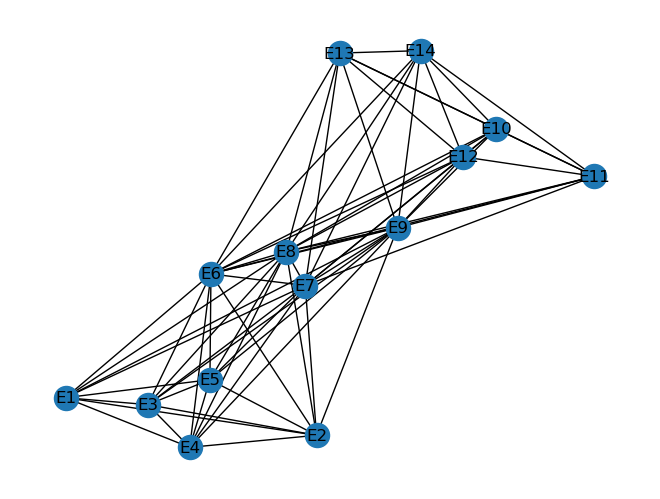

In [128]:
pos = nx.spring_layout(G, seed=648)  # Seed layout for reproducible node positions
nx.draw(C, pos,with_labels=True)
plt.show()

Page Rank measures the relative importance of the events. Events 8, 7, 9, 6 and are again highly important, probably because they had more attendees so there is more oppurtunites for overlapping connections between the women.

In [129]:
Event_weighted = bipartite.weighted_projected_graph(G, clubs)
pagerank_weighted = nx.pagerank(Event_weighted, weight='weight')

print("PageRank, Event")
sorted_weighted = sorted(pagerank_weighted.items(), key=lambda x: x[1], reverse=True)
for club, score in sorted_weighted:
    print(f"{score:.4f} {club}  ")

PageRank, Event
0.1280 E8  
0.1065 E7  
0.1036 E9  
0.0915 E6  
0.0845 E5  
0.0729 E3  
0.0677 E12  
0.0618 E10  
0.0552 E4  
0.0493 E2  
0.0474 E13  
0.0474 E14  
0.0474 E1  
0.0368 E11  


It was originally all connected. I raised the number of shared attendees until the graph started looking more sparse. I guess this does cause it to skew towards the most attended events.

In [130]:
E_filtered = nx.Graph() #new graph
E_filtered.add_nodes_from(Event_weighted.nodes())
for u, v, data in Event_weighted.edges(data=True):
    if data['weight'] >= 6: #where women went to atleast 6 events together
        E_filtered.add_edge(u, v)

e_cliques = list(nx.find_cliques(E_filtered)) #find the cliques in this new group

In [131]:
print("Events where they shares at least 6 women:")
for i, e_cliques in enumerate(e_cliques, 1):
    if len(e_cliques) >= 2: #just look for 2+ event groups
        print(f"Clique {i}: {e_cliques}")

Events where they shares at least 6 women:
Clique 3: ['E8', 'E5', 'E7']
Clique 4: ['E8', 'E5', 'E6']
Clique 5: ['E8', 'E9']
Clique 8: ['E3', 'E5']


E3 looks like the first event where there is continued attendence from a similar group, as 6 of them also go to Event 5.

Event 8 looks like it was a important meeting event. 6 of the women who went to Event 8, were also at Event 5, 6, 7, and 9. 

Interestingly if we increase to 7 similar attendees, we see that Event 7 and 9 although both also having 13 attendees total did not have 7 attendees in common, showing Event 8 was the event with the most tenured and overlapping attendees from all the other events, that was a "regulars" event.

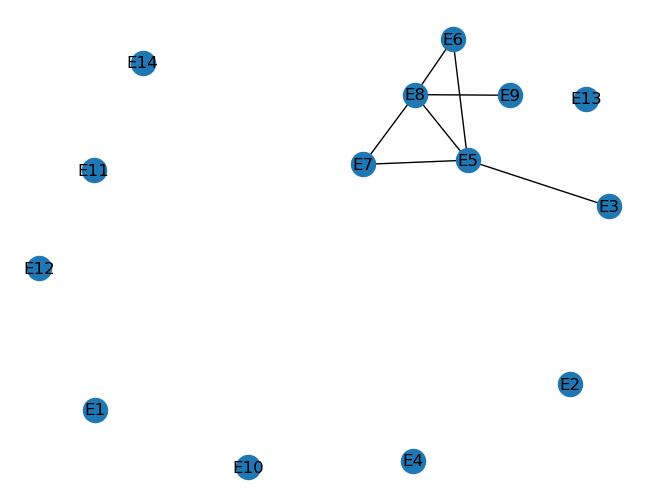

In [124]:
#Strong connection between events where atleast 4 women were grouped together
pos = nx.spring_layout(E_filtered,k=0.8, seed=648)
nx.draw(E_filtered, pos,with_labels=True,)
plt.show()